In [2]:
import numpy as np 
import os
from pathlib import Path
import sys, os
import matplotlib.pyplot as plt
sys.path.append(os.path.join(os.getcwd(), '..'))

In [3]:
from utils.eda_helpers import read_csv_numeric

file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')
x_indices, x_data = read_csv_numeric(os.path.join(DATA_FOLDER, "x_train.csv"))
y_indices, y_data = read_csv_numeric(os.path.join(DATA_FOLDER, "y_train.csv"))

In [5]:
del x_indices["Id"]
del y_indices["Id"]

In [6]:
from utils.eda_helpers import clean_data
x_data = clean_data(x_data, x_indices)

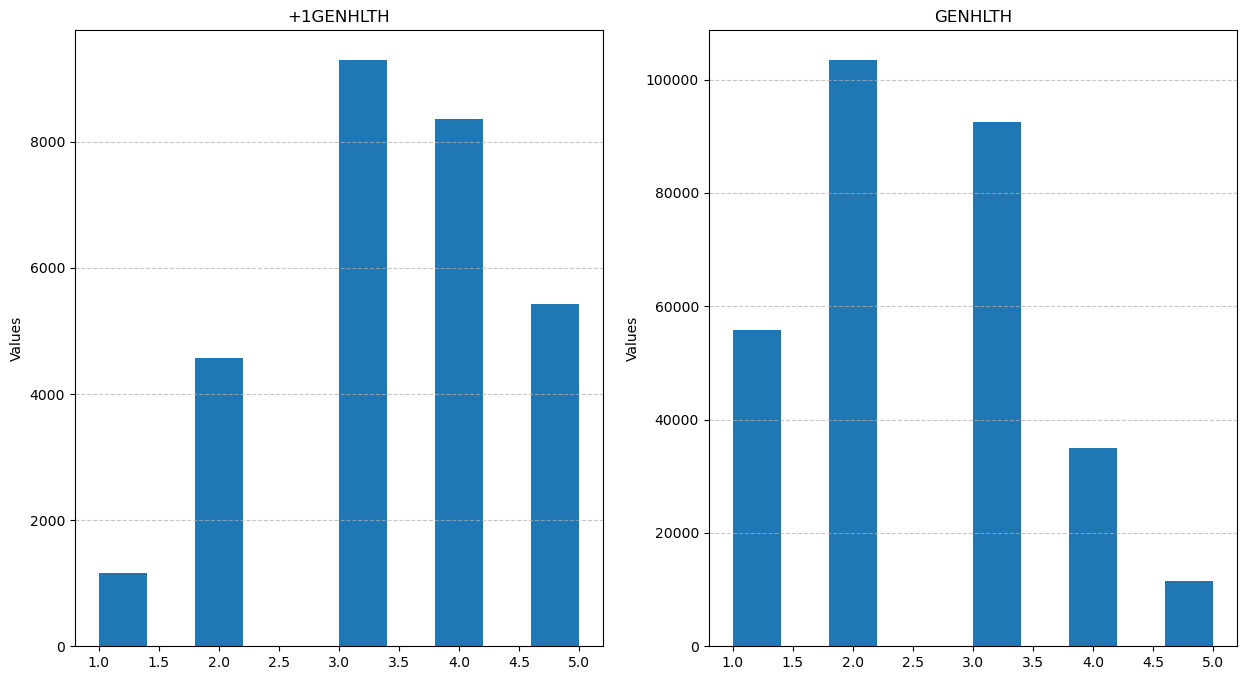

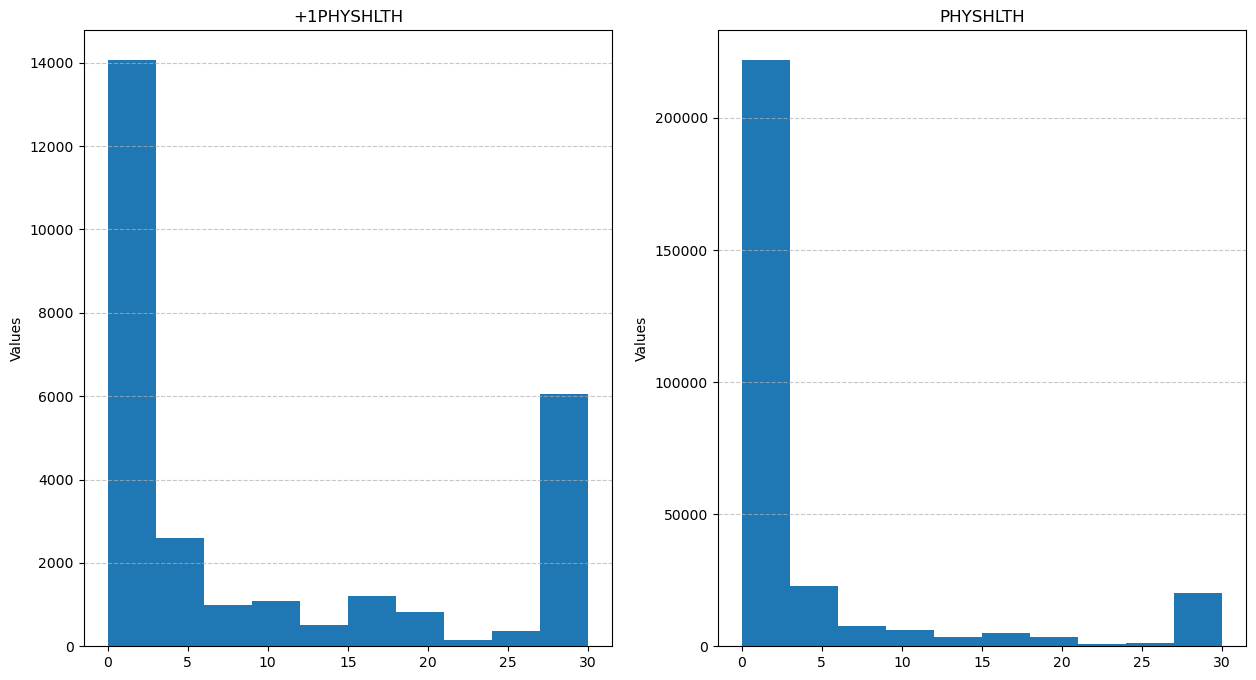

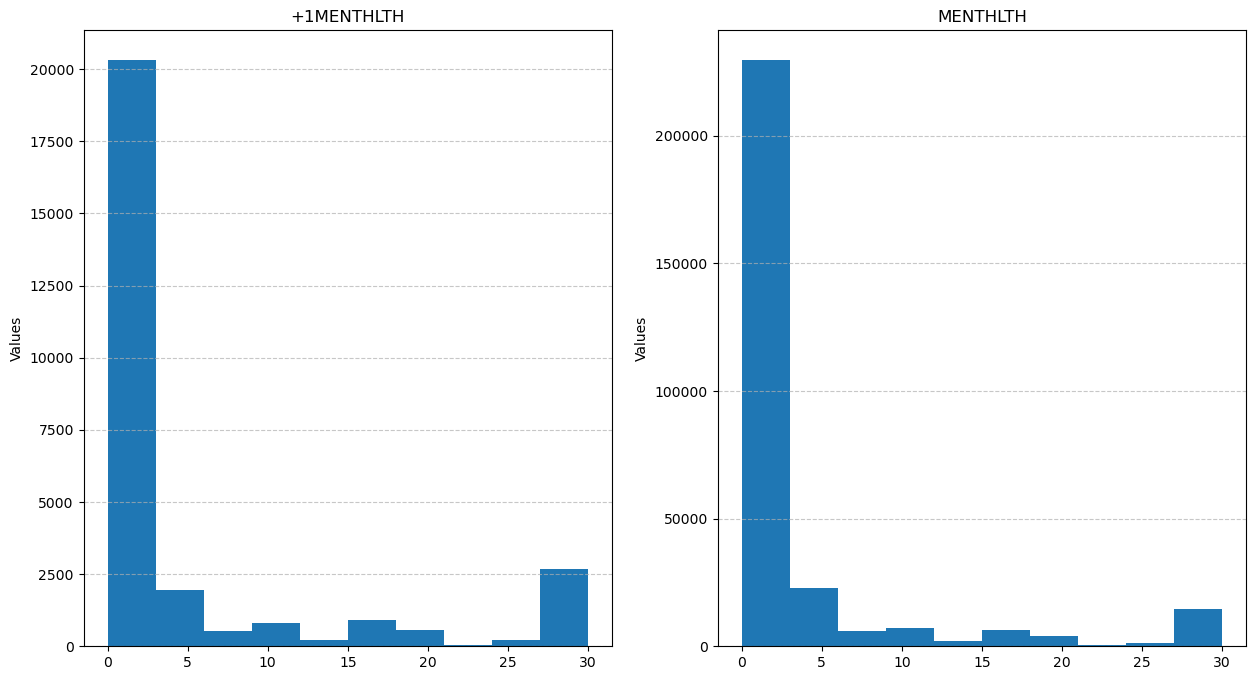

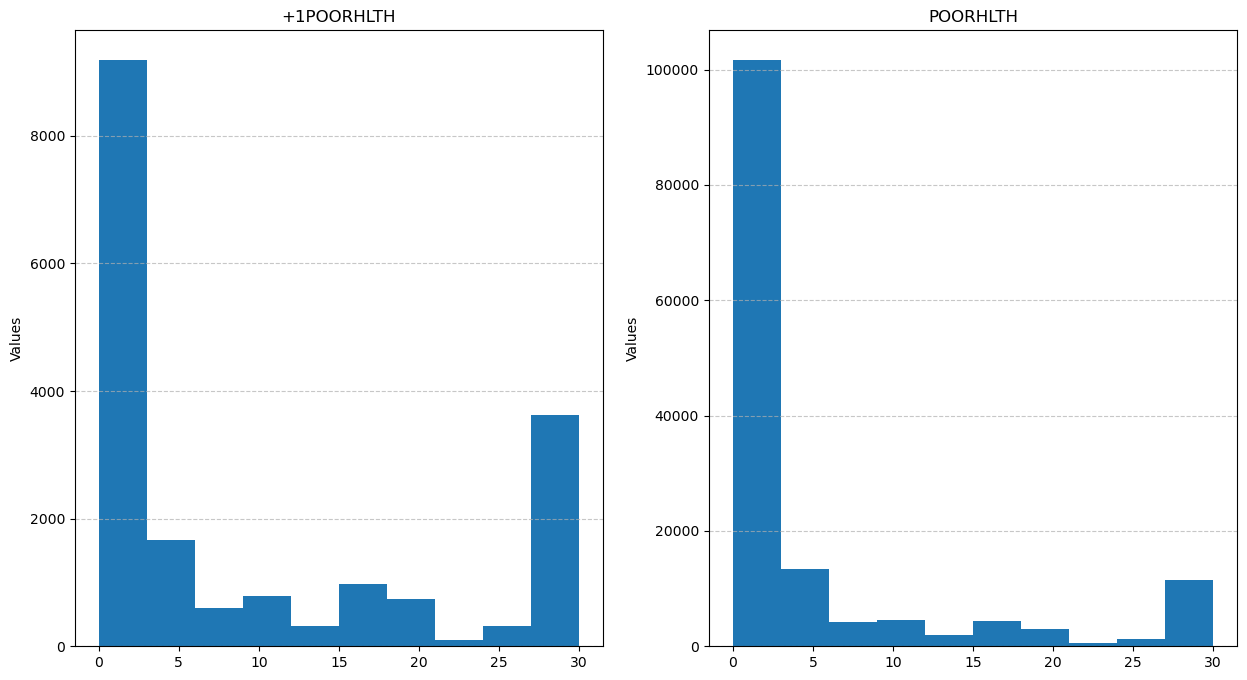

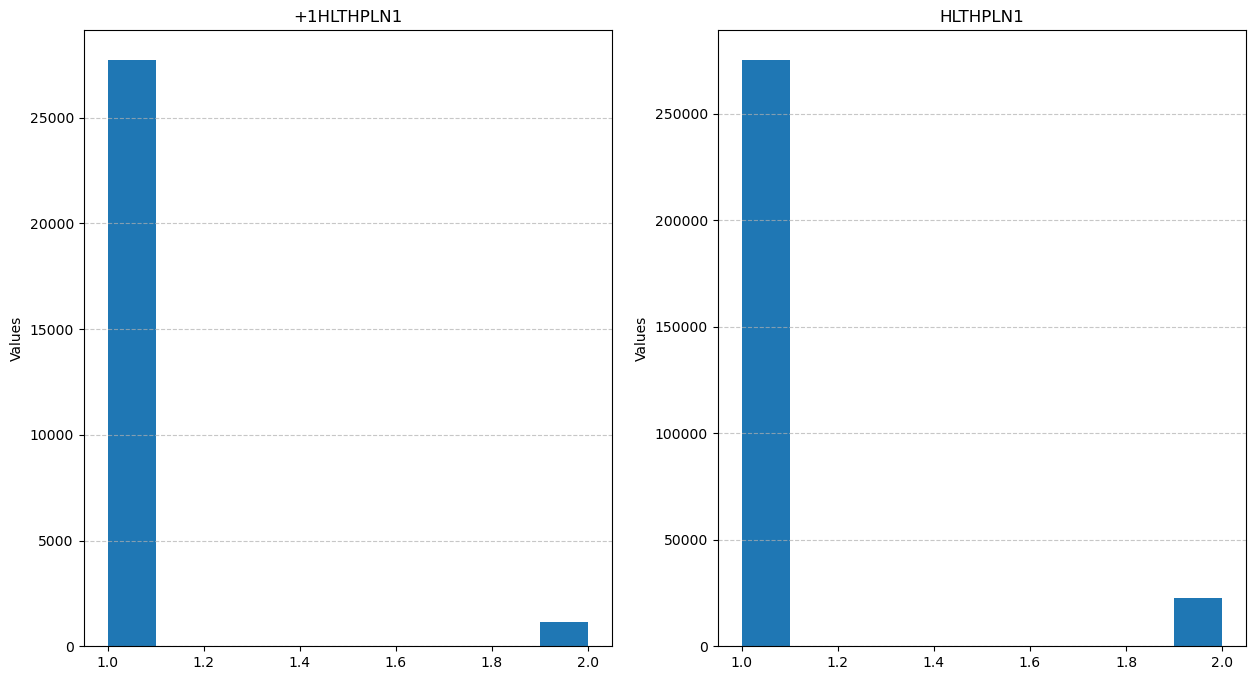

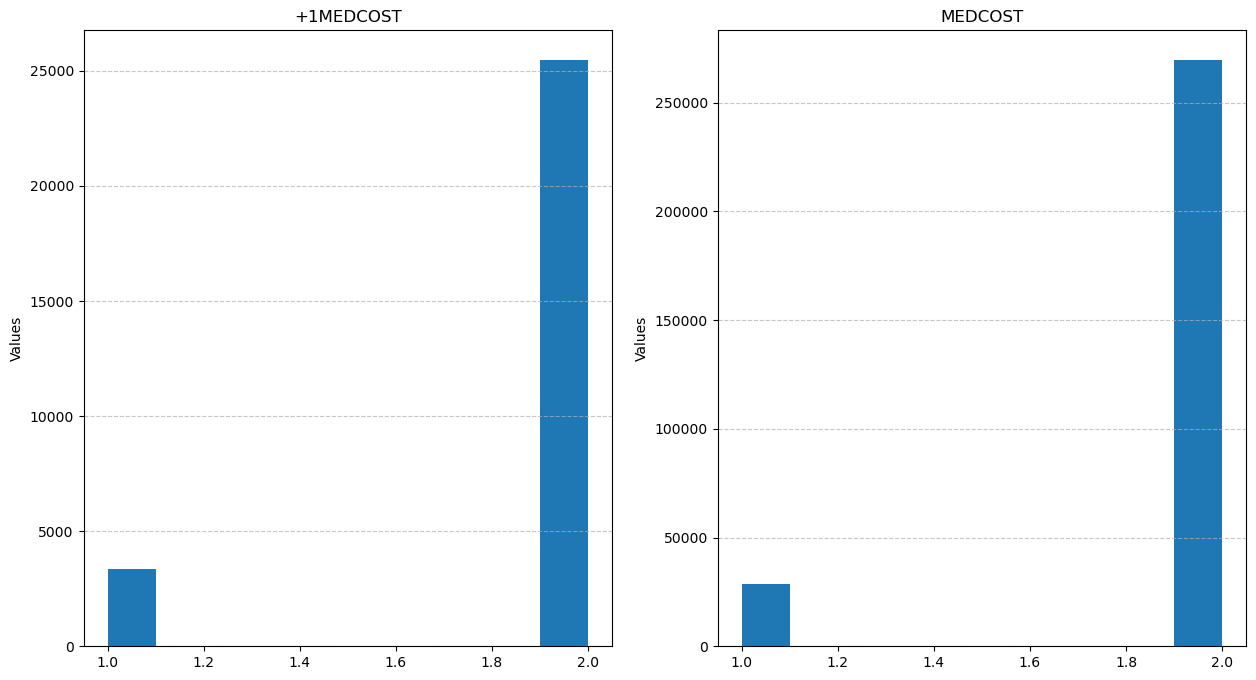

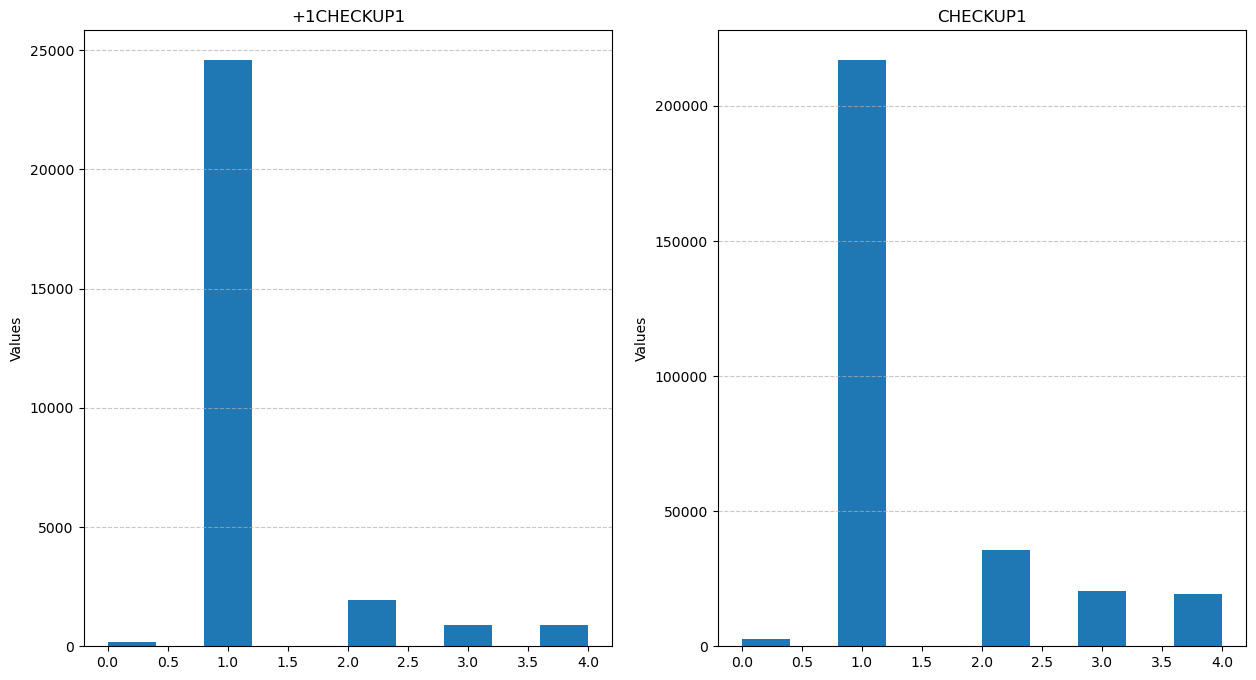

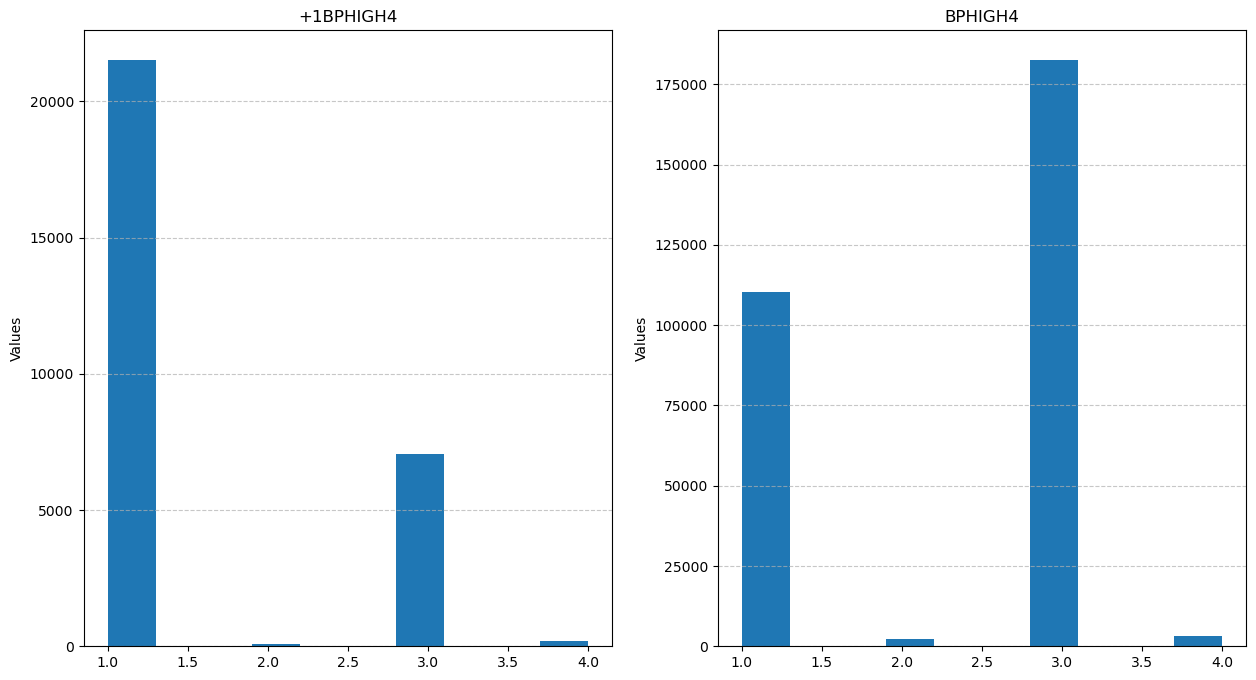

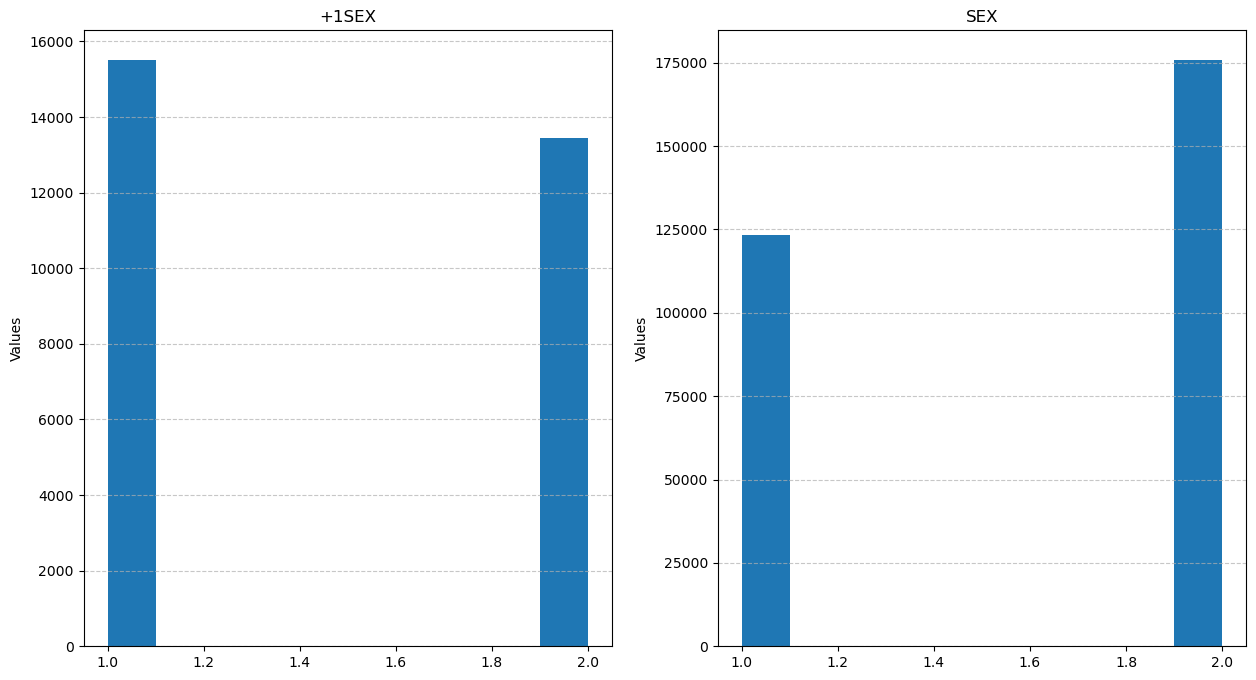

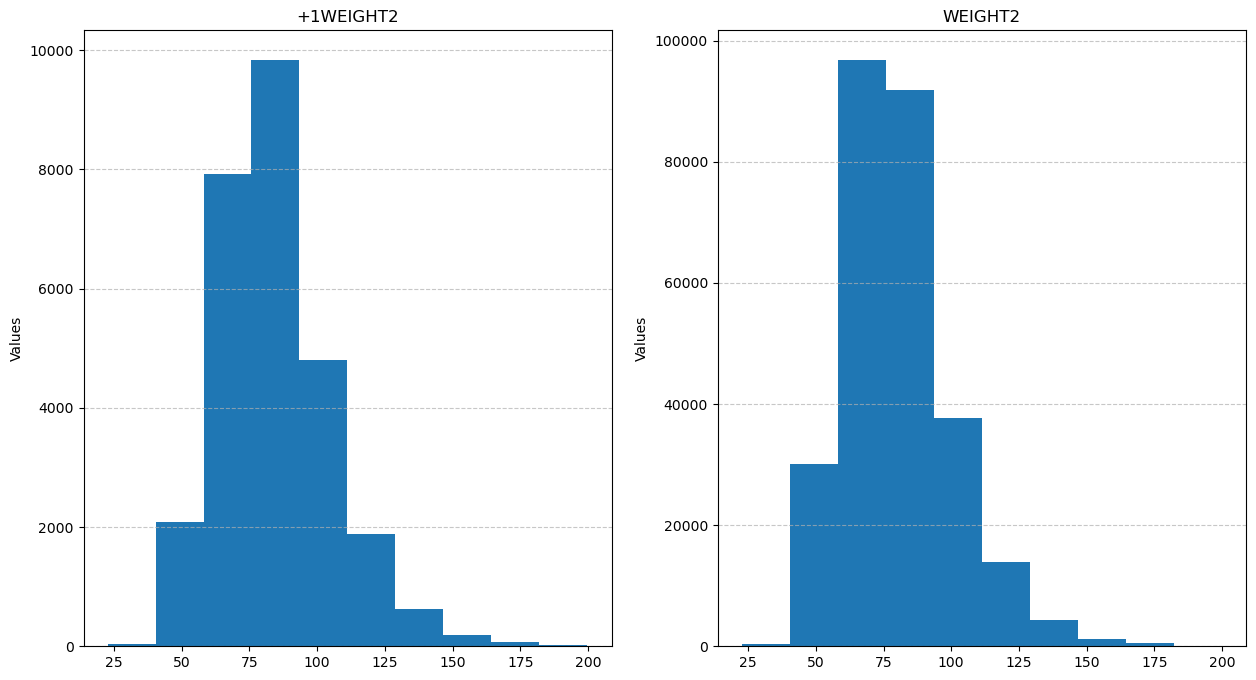

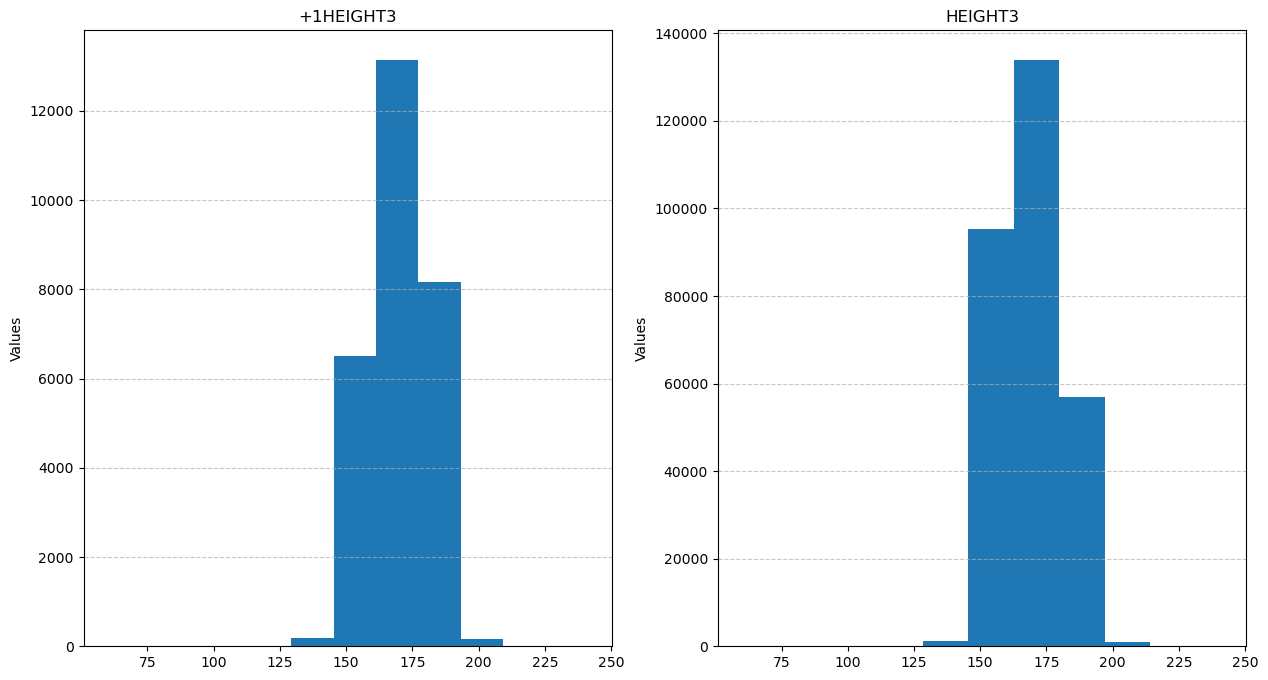

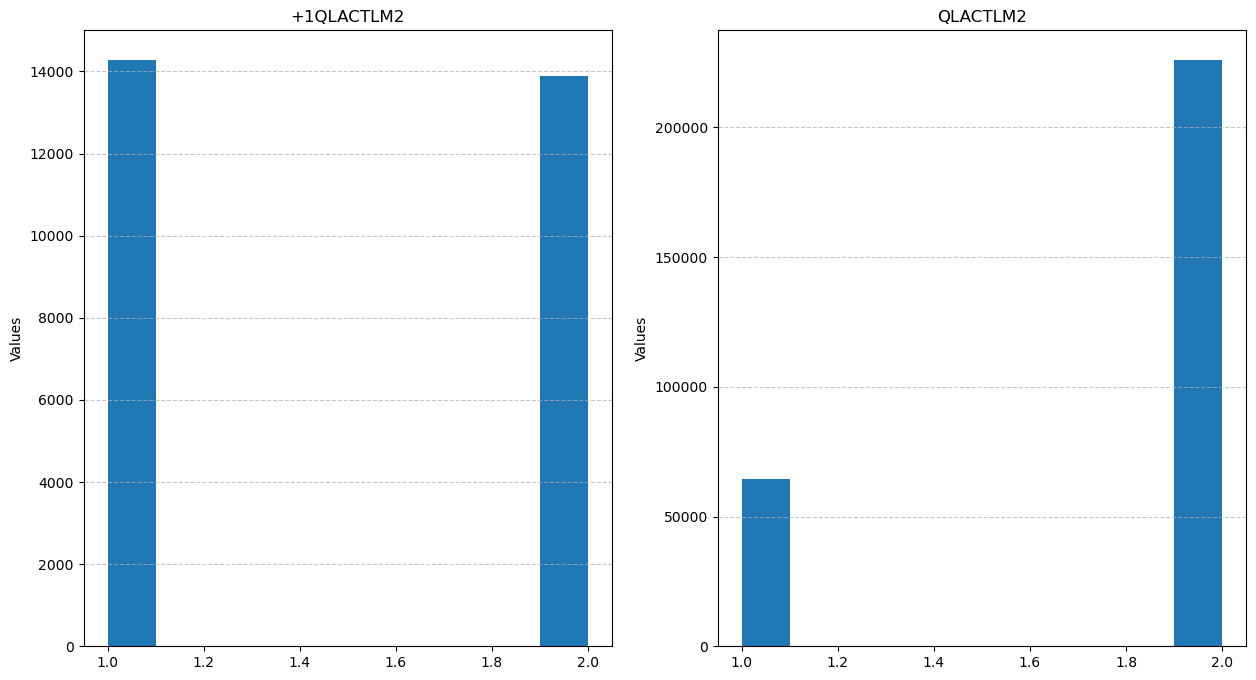

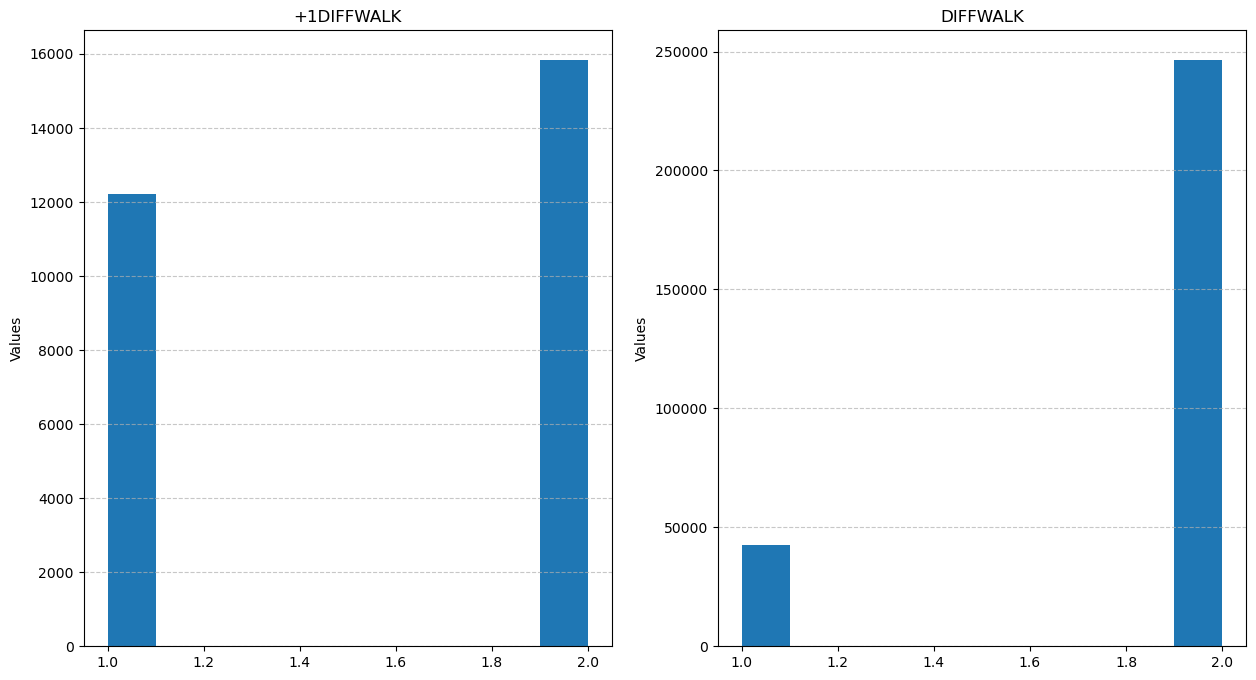

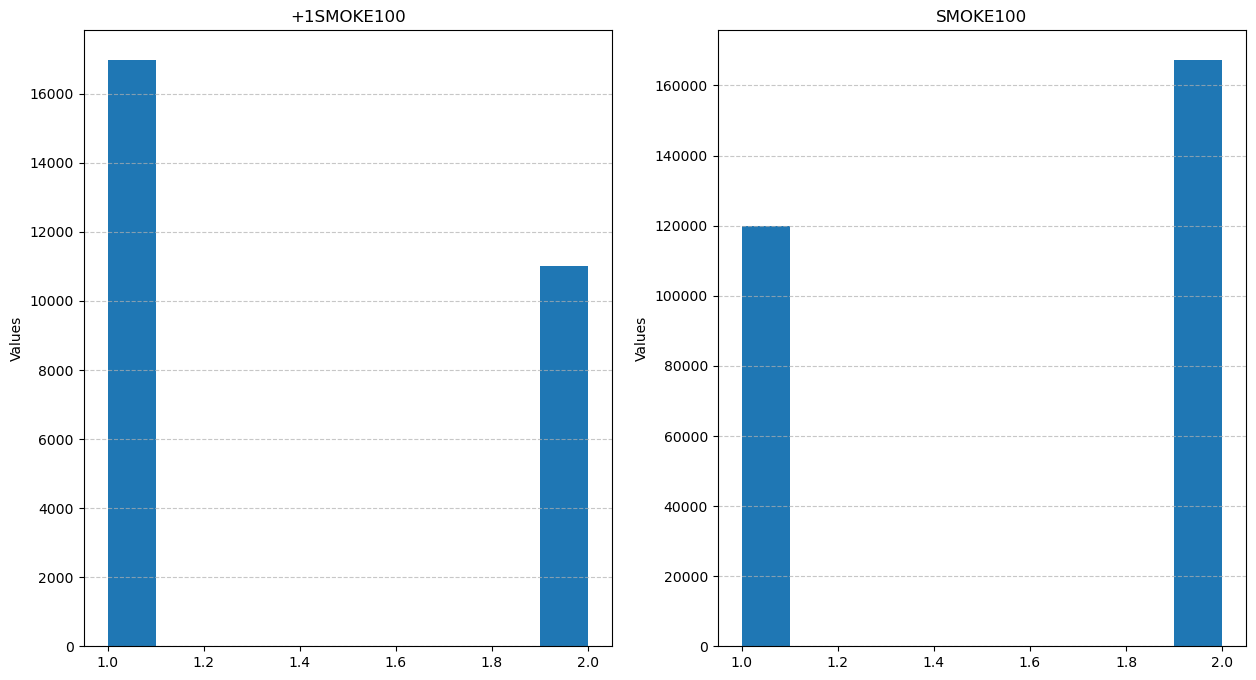

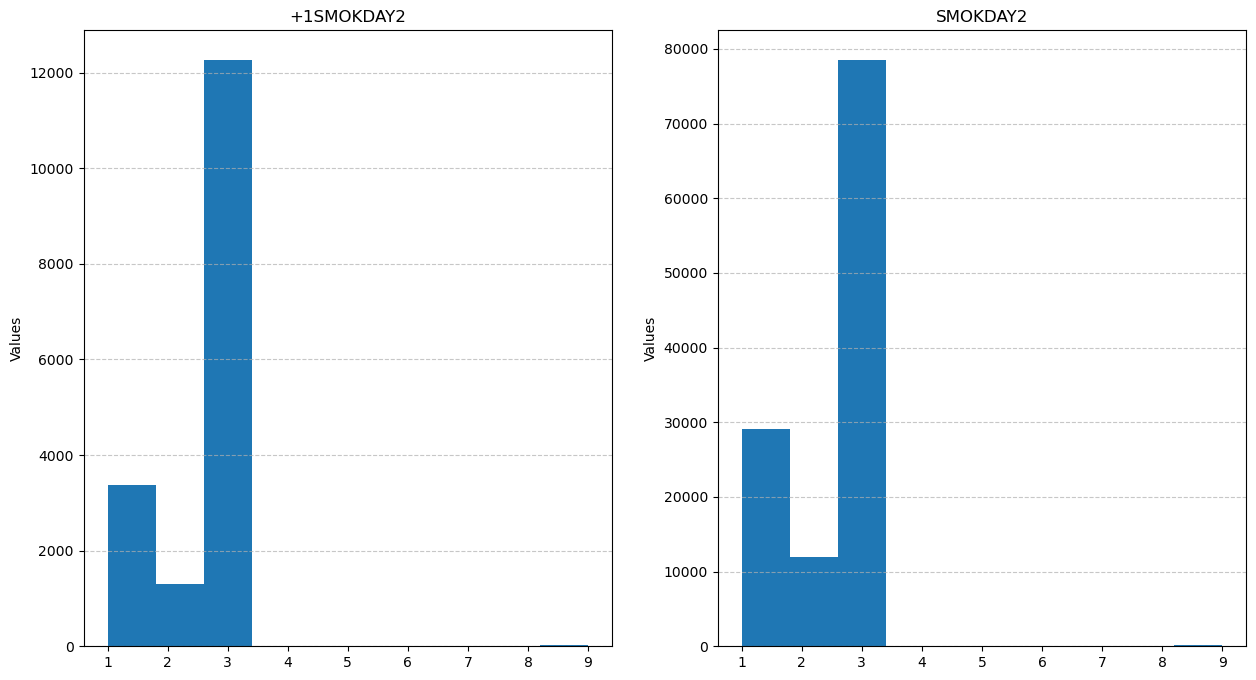

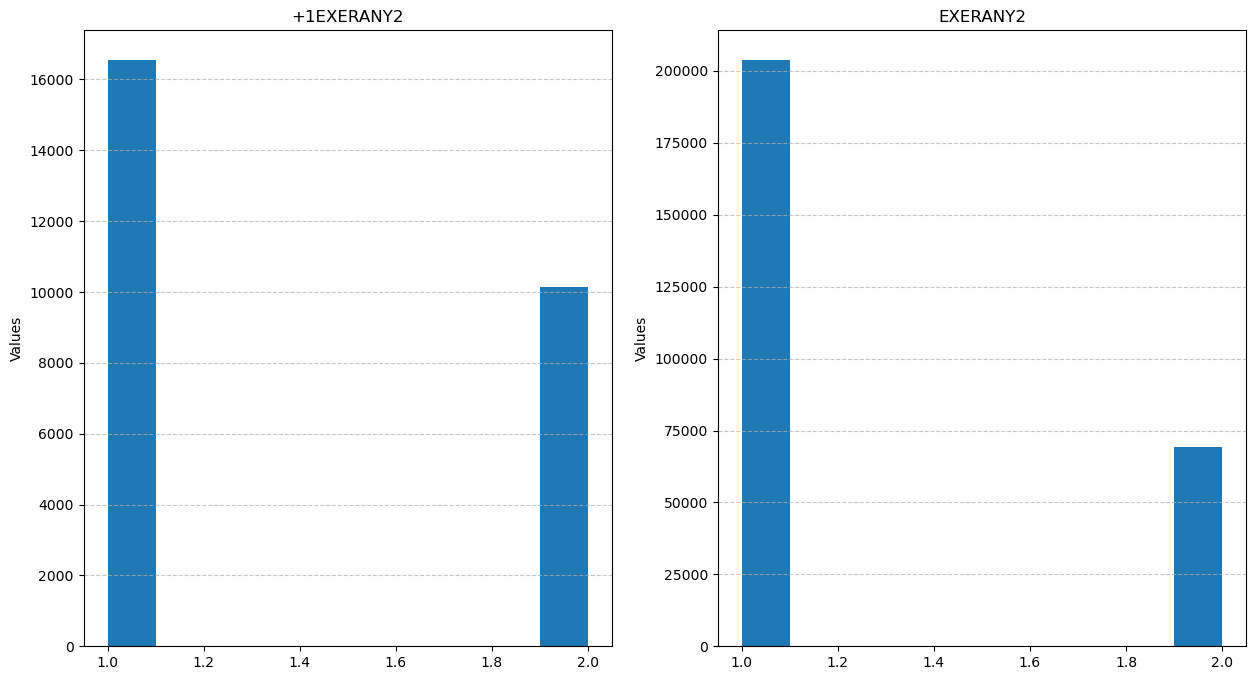

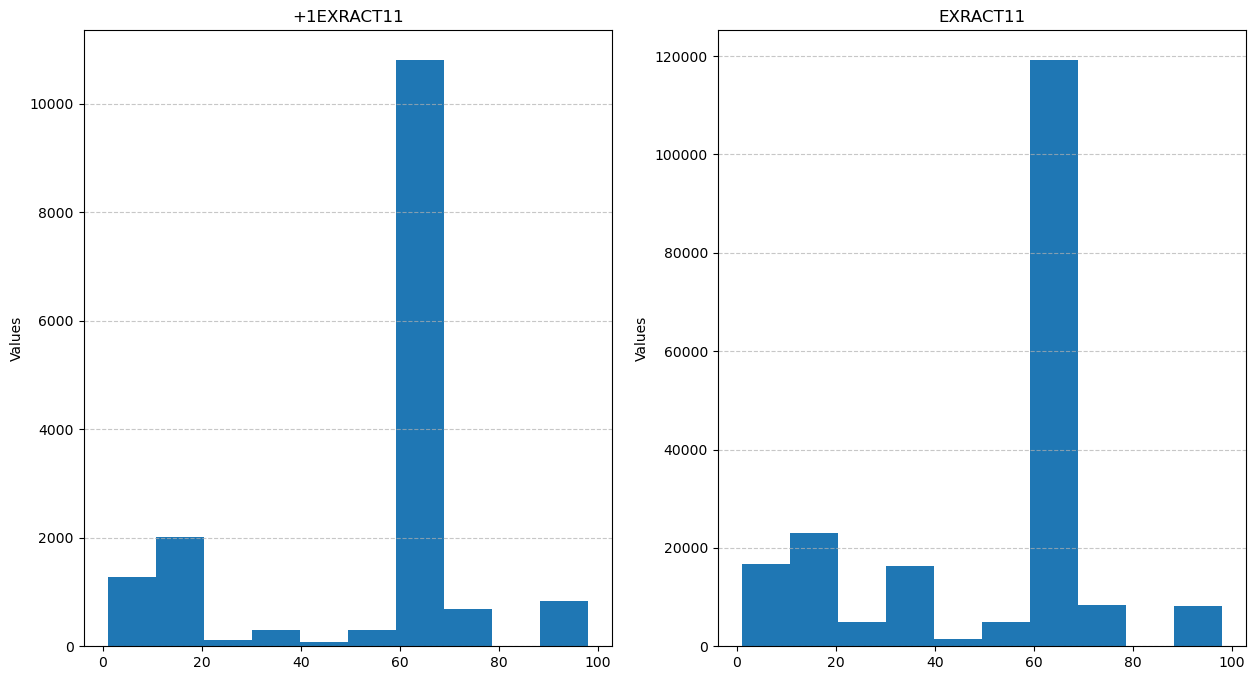

In [7]:
interesting_columns = ["GENHLTH", "PHYSHLTH", "MENTHLTH", "POORHLTH", "HLTHPLN1", "MEDCOST", "CHECKUP1",
                        "BPHIGH4", "SEX", "WEIGHT2", "HEIGHT3", "QLACTLM2", 
                        "DIFFWALK", "SMOKE100", "SMOKDAY2", "EXERANY2", "EXRACT11"]

for c in interesting_columns:
    m = y_data[:, 1] == 1
    m2 = y_data[:, 1] == -1

    fig, axes = plt.subplots(1, 2, sharex="all", sharey="none", figsize=(15, 8))
    axes.flatten()[0].hist(x_data[m, x_indices[c]], bins=10)
    axes[0].set_title("+1" + str(c))
    axes.flatten()[0].set_ylabel("Values")
    axes.flatten()[0].grid(axis='y', linestyle='--', alpha=0.7)
    axes.flatten()[1].hist(x_data[m2, x_indices[c]])
    axes[1].set_title("-1" + str(c))
    axes.flatten()[1].set_ylabel("Values")
    axes.flatten()[1].grid(axis='y', linestyle='--', alpha=0.7)
    # plt.boxplot([x_data[m, x_indices[c]], x_data[m2, x_indices[c]]], labels=["1", "-1"])

    plt.title(c)
    plt.ylabel("Values")
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.show()

In [8]:
nans = np.isnan(x_data).sum(axis=0)
cols_with_nans = []

for index, nas in enumerate(nans):
    if nas > 150000:
        for k, v in x_indices.items():
            if v == index:
                print("Column " + str(k) + " has " + str(nas) + " NAs")
                cols_with_nans.append(k)
                break

print((set(interesting_columns) & set(cols_with_nans)))

Column COLGHOUS has 328103 NAs
Column LADULT has 328103 NAs
Column CTELNUM1 has 188720 NAs
Column CELLFON2 has 188720 NAs
Column CADULT has 188721 NAs
Column PVTRESD2 has 188720 NAs
Column CCLGHOUS has 327334 NAs
Column CSTATE has 188719 NAs
Column LANDLINE has 189526 NAs
Column HHADULT has 192967 NAs
Column POORHLTH has 163417 NAs
Column BPMEDS has 196550 NAs
Column ASTHNOW has 285503 NAs
Column DIABAGE2 has 286238 NAs
Column NUMPHON2 has 318245 NAs
Column PREGNANT has 280029 NAs
Column SMOKDAY2 has 191379 NAs
Column STOPSMK2 has 282666 NAs
Column LASTSMK2 has 237993 NAs
Column AVEDRNK2 has 173523 NAs
Column DRNK3GE5 has 173414 NAs
Column MAXDRNKS has 176367 NAs
Column EXEROFT2 has 182913 NAs
Column EXERHMM2 has 184643 NAs
Column LMTJOIN3 has 228132 NAs
Column ARTHDIS2 has 230034 NAs
Column ARTHSOCL has 227197 NAs
Column JOINPAIN has 231022 NAs
Column FLSHTMY2 has 195038 NAs
Column IMFVPLAC has 186506 NAs
Column HIVTSTD3 has 261382 NAs
Column WHRTST10 has 245215 NAs
Column PDIABTST ha

In [9]:
all_columns = ['FLSHTMY2','HIVTSTD3', 'PA1VIGM_','PAFREQ2_','WTKG3', 'AVEDRNK2','BEANDAY_','FRUTDA1_','FTJUDA1_','GRENDAY_','HEIGHT3','ORNGDAY_',
    'VEGEDA1_','WEIGHT2','_BMI5','_BMI5CAT','_RFBMI5', 'ALCDAY5','ASACTLIM','ASNOSLEP','BLDSUGAR','CDHELP','DRNK3GE5','DRNKANY5','EXERHMM1','EXERHMM2','EXEROFT1','EXEROFT2','FEETCHK2',
    'FRUIT1','FRUITJU1','FVBEANS','FVGREEN','FVORANG','LONGWTCH','MAXDRNKS','STRENGTH','VEGETAB1','_LMTSCL1','_RFBING5','ADANXEV','ADDOWN','ADEAT1','ADENERGY','ADFAIL','ADMOVE','ADPLEASR','ADSLEEP','ADTHINK','ARTHSOCL','ARTTODAY','ASINHALR','ASRCHKUP',
    'ASTHMAGE','CAREGIV1','CASTHDX2','CDDISCUS','CDSOCIAL','CHKHEMO3','CRGVEXPT','CRGVHOUS','CRGVPERS','CRGVPRB1','CRGVREL1','CVDINFR4',
    'DIABAGE2','DIABETE3','DOCTDIAB','EMTSUPRT','EXRACT11','EXRACT21','FC60_','FEETCHK','HAREHAB1','HHADULT','HOWLONG','HPVADVC2',
    'IMFVPLAC','INCOME2','JOINPAIN','LASTSIG3','LASTSMK2','LENGEXAM','LSTBLDS3','MAXVO2_','MENTHLTH','PAFREQ1_','PERSDOC2','PHYSHLTH',
    'POORHLTH','PSATIME','RDUCHART','SCNTLWK1','SCNTWRK1','SXORIENT','TRNSGNDR','VETERAN3','VINOCRE2','WHRTST10','_ASTHMS1','_CRACE1',
    '_DRDXAR1','_EDUCAG','_PNEUMO2','_PRACE1','_RACE','_RACE_G1','_WT2RAKE','ADDEPEV2','ARTHDIS2','ARTHEDU','ARTHEXER','ARTHWGT','ASATTACK','ASDRVIST','ASERVIST','ASPUNSAF','ASTHMA3','ASTHMED3','ASYMPTOM',
    'BLDSTOOL','BLIND','BLOODCHO','BPHIGH4','CASTHNO2','CDASSIST','CDHOUSE','CHCCOPD1','CHCKIDNY','CHECKUP1','CHOLCHK','CIMEMLOS',
    'CPDEMO1','CRGVHRS1','CRGVMST2','DECIDE','DIABEDU','DIABEYE','DIFFALON','DRADVISE','EDUCA','EXERANY2','EYEEXAM','FLUSHOT6',
    'HADHYST2','HADMAM','HADPAP2','HADSGCO1','HADSIGM3','HAVARTH3','HIVTST6','HLTHPLN1','HPVADSHT','HPVTEST','LANDLINE','LMTJOIN3',
    'MEDCOST','MISTMNT','NUMHHOL2','PCPSAAD2','PCPSADE1','PCPSADI1','PCPSARE1','PDIABTST','PNEUVAC3','PREDIAB1','PROFEXAM','QLACTLM2',
    'RENTHOM1','SCNTLPAD','SCNTMEL1','SCNTMNY1','SCNTPAID','SEATBELT','SMOKE100','STOPSMK2','STREHAB1','STRFREQ_','TETANUS','TOLDHI2',
    'USEEQUIP','USENOW3','VICTRCT4','VIDFCLT2','VIEYEXM2','VIGLUMA2','VIMACDG2','VIPRFVS2','VIREDIF3','WTCHSALT','_CHOLCHK','_HCVU651',
    '_LLCPWT','_LMTACT1','_MICHD','_PA150R2','_PA30021','_PA300R2','_PASTRNG','_RACEG21','_RFCHOL','_RFDRHV5','_RFHYPE5','_RFSEAT2',
    '_SMOKER3','_TOTINDA','_VEGESUM','ACTIN11_','ACTIN21_','ASTHNOW','BPMEDS','CADULT','CCLGHOUS','CELLFON2','CELLFON3','CHCOCNCR','CHCSCNCR','CHILDREN','COLGHOUS',
    'CRGVLNG1','CSTATE','CTELENUM','CTELNUM1','CVDASPRN','CVDCRHD4','CVDSTRK3','DIFFDRES','DIFFWALK','DISPCODE','DROCDY3_','EMPLOY1',
    'EXACTOT1','EXACTOT2','EXRACT11','EXRACT21','FMONTH','GENHLTH','HPLSTTST','HTIN4','HTM4','IDATE','IDAY','IMONTH','INSULIN',
    'INTERNET','IYEAR','LADULT','LASTPAP2','LSATISFY','MARITAL','METVL11_','METVL21_','MSCODE','NUMADULT','NUMMEN','NUMPHON2','NUMWOMEN',
    'PA1MIN_','PADUR1_','PADUR2_','PAINACT2','PAMIN11_','PAMIN21_','PAMISS1_','PAVIG11_','PAVIG21_','PCDMDECN','PCPSARS1','PREGNANT',
    'PSATEST1','PVTRESD1','PVTRESD2','QLHLTH2','QLMENTL2','QLSTRES2','QSTLANG','QSTVER','RCSGENDR','RCSRLTN2','RDUCSTRK','RLIVPAIN',
    'SEQNO','SEX','SHINGLE2','SMOKDAY2','STATERES','VIINSUR2','_AGE65YR','_AGE80','_AGEG5YR','_AGE_G','_AIDTST3','_CASTHM1','_CHISPNC',
    '_CHLDCNT','_CLLCPWT','_CPRACE','_DRNKWEK','_DUALCOR','_DUALUSE','_FLSHOT6','_FRT16','_FRTLT1','_FRTRESP','_FRUITEX','_FRUTSUM',
    '_HISPANC','_INCOMG','_LMTWRK1','_LTASTH1','_MINAC11','_MINAC21','_MISFRTN','_MISVEGN','_MRACE1','_PACAT1','_PAINDX1','_PAREC1',
    '_PASTAE1','_PSU','_RACEGR3','_RAWRAKE','_RFHLTH','_RFSEAT3','_RFSMOK3','_STATE','_STRWT','_STSTR','_VEG23','_VEGETEX','_VEGLT1',
    '_VEGRESP']

missing_columns = []

for c in all_columns:
    if c not in x_indices:
        missing_columns.append(c)


for c in x_indices:
    if c not in all_columns:
        print("Column " + str(c) + " is not in all columns")

print(", ".join(missing_columns))

CVDINFR4, _MICHD, CVDCRHD4, EXACTOT1, EXACTOT2, PAINACT2, QLHLTH2, QLMENTL2, QLSTRES2


In [ ]:
# columns that have nothing to do with data
no_columns = ["_STATE", "FMONTH", "IDATE", "IMONTH", "IDAY", 
              "IYEAR", "DISPCODE", "SEQNO", "_PSU", "CTELENUM",
              "PVTRESD1", "COLGHOUS", "STATERES", "CELLFON3", 
              "CTELNUM1", "CELLFON2", "CADULT", "LANDLINE", "CSTATE",
              "NUMHHOL2", "NUMPHON2", "CPDEMO1", "INTERNET", "SEATBELT", 
              "SCNTMNY1", "SCNTMEL1", "SCNTLPAD", "SCNTPAID", "SCNTWRK1",
              "SCNTLWK1", "RCSGENDR", "RCSRLTN2", "QSTVER", "QSTLANG", 
              "_STSTR", "_STRWT", "_RAWRAKE", "_WT2RAKE", "_DUALUSE",
              "_DUALCOR", "_LLCPWT", "CVDINFR4", "_MICHD", "CVDCRHD4", 
              "EXACTOT1", "EXACTOT2", "PAINACT2", "QLHLTH2", "QLMENTL2", "QLSTRES2"]

# columns that have data but seem not interesting to us
not_interesting = ["LADULT", "NUMADULT", "NUMMEN", "NUMWOMEN", 
                   "PVTRESD2", "CCLGHOUS", "HHADULT", "MARITAL", 
                   "EDUCA", "RENTHOM1", "CHILDREN", "CAREGIV1", 
                   "CRGVREL1", "CRGVLNG1", "CRGVHRS1", "CRGVPRB1", 
                   "CRGVPERS", "CRGVHOUS", "CRGVMST2", "CRGVEXPT",
                   "LENGEXAM", "_CHISPNC", "_CRACE1", "_CPRACE",
                   "_CLLCPWT"]

# other columns we could include (for now):
other_keep = ["MARITAL", "EDUCA", "RENTHOM1", "CHILDREN", "_CRACE1",
             "SCNTMEL1", "SCNTWRK1"]

# columns we could work with
remaining_columns = list(set(all_columns) - set(no_columns) - set(not_interesting))
remaining_columns = list(set(remaining_columns) | set(other_keep)) 

# remove columns with high N/A counts where N/A actually has no meaning
na_cols = []
na_cols_extreme = [] # super high missing, absolutely remove

for c in remaining_columns:
    na_perc = np.isnan(x_data[:, x_indices[c]]).sum(axis=0)/x_data[:, x_indices[c]].shape[0]
    if na_perc > 0.7:
       na_cols.append(c)
    if na_perc > 0.95 : 
        na_cols_extreme.append(c)

na_cols_moderate = list(set(na_cols) - set(na_cols_extreme)) # between 0.7 and 0.95
remaining_columns = list(set(remaining_columns) - set(na_cols))
len(remaining_columns)

161

In [11]:
# above 0.95, remove at all cost
print(len(na_cols_extreme))
print(na_cols_extreme)

64
['HPVADSHT', 'ADSLEEP', 'ADENERGY', 'HPLSTTST', 'ASPUNSAF', 'VIPRFVS2', 'VIINSUR2', 'ADFAIL', 'RDUCSTRK', 'ADMOVE', 'ADTHINK', 'MISTMNT', 'VIREDIF3', 'CVDASPRN', 'ASRCHKUP', 'ADEAT1', 'ARTHEDU', 'ASYMPTOM', 'HPVADVC2', 'ARTTODAY', 'STREHAB1', 'ADPLEASR', 'ASNOSLEP', 'VIDFCLT2', 'HPVTEST', 'PSATEST1', 'CDASSIST', 'VINOCRE2', 'HAREHAB1', 'PCPSARE1', 'RLIVPAIN', 'CDDISCUS', 'LSATISFY', 'ADDOWN', 'ASTHMAGE', 'PCPSADE1', 'CDHELP', 'CASTHNO2', 'VIGLUMA2', 'HOWLONG', 'ASINHALR', 'VIMACDG2', 'CDHOUSE', 'PCPSARS1', 'LASTPAP2', 'ASACTLIM', 'VIEYEXM2', 'CDSOCIAL', 'ASTHMED3', 'VICTRCT4', 'PSATIME', 'ASATTACK', 'PCDMDECN', 'PCPSADI1', 'ASERVIST', 'ADANXEV', 'PCPSAAD2', 'ARTHEXER', 'ARTHWGT', 'LSTBLDS3', 'RDUCHART', 'ASDRVIST', 'PROFEXAM', 'EMTSUPRT']


In [12]:
# between 0.7 and 0.95 (still removed)
print(len(na_cols_moderate))
print(na_cols_moderate)

37
['INSULIN', 'FEETCHK', 'STOPSMK2', 'HADMAM', 'FEETCHK2', 'LASTSMK2', 'SHINGLE2', 'DIABAGE2', 'DOCTDIAB', 'DIABEDU', 'ASTHNOW', 'HADSIGM3', 'DRADVISE', 'LONGWTCH', 'SCNTMEL1', 'JOINPAIN', 'CHKHEMO3', 'PREDIAB1', 'CIMEMLOS', 'HIVTSTD3', 'HADPAP2', 'PREGNANT', 'EYEEXAM', 'PDIABTST', 'LASTSIG3', 'TETANUS', '_CRACE1', 'ARTHDIS2', 'WHRTST10', 'HADSGCO1', 'HADHYST2', 'DIABEYE', 'SCNTWRK1', 'CASTHDX2', 'BLDSUGAR', 'WTCHSALT', 'BLDSTOOL']


In [ ]:
# reconsider keeping from columns having between 0.7 and 0.95 NA values
reconsider_keep = [
    # sodium/salt-related behavior
    "WTCHSALT", 
    "LONGWTCH",  
    "DRADVISE",  

    # diabetes management & awareness 
    "INSULIN",   
    "DOCTDIAB",  
    "DIABAGE2",  
    "FEETCHK",   
    "FEETCHK2", 
    "CHKHEMO3", 
    "PREDIAB1",  

    # lifestyle and behavior
    "STOPSMK2",  
    "SCNTWRK1",  

    # demographics
    "_CRACE1",  
]
len(reconsider_keep)

13

In [14]:
# add back to remaining variables for now
remaining_columns = list(set(remaining_columns) | set(reconsider_keep))
len(remaining_columns)

174

In [ ]:
# deleting columns because they have overlapping data (from calculations etc.)
# some are also excluded because their calculated variable is easier to understand 

calc_columns = ["_FLSHOT6", "_PNEUMO2", "IMFVPLAC", "_CHOLCHK", "FTJUDA1_", "FRUITJU1", "FVORANG", "FVBEANS", "FVGREEN",
                "VEGETAB1", "_VEG23", "_FRT16", "_FRTRESP", "_VEGRESP", "_VEGLT1", "_FRTLT1", "_AGE65YR", "_AGE_G", "_AGEG5YR",
                "_HISPANC", "_RACEGR3", "_RACEG21", "_RACE", "_PRACE1", "_INCOMG", "_EDUCAG", "_BMI5CAT", "HEIGHT3", "HTIN4",
                "WEIGHT2", "HLTHPLN1", "_CHLDCNT", "EXEROFT1", "EXEROFT2", "EXERHMM1", "EXERHMM2", "_PA150R2", "_PA300R2", 
                "_PA30021", "STRENGTH", "ACTIN11_", "ACTIN21_", "_RFCHOL", "_RFHYPE5", "_RFHLTH" "_RFSEAT2", "_RFSEAT3",
                "_RFBMI5", "_RFBING5", "_RFSMOK3", "_RFDRHV5", "ASTHMA3", "_LTASTH1", "_DRDXAR1", "RFBING5", "_DRDXAR1",
                "_HCVU651"]

after_duplicates_columns = list(set(remaining_columns) - set(calc_columns))
len(after_duplicates_columns)

print('\n'.join(after_duplicates_columns))
print(len(after_duplicates_columns))

VETERAN3
STOPSMK2
BLIND
WTKG3
CHCCOPD1
EDUCA
_SMOKER3
CHKHEMO3
METVL11_
_LMTSCL1
SEX
_RFSEAT2
_ASTHMS1
_PASTRNG
TOLDHI2
CVDSTRK3
LMTJOIN3
_DRNKWEK
FLUSHOT6
_FRUITEX
PA1VIGM_
CHILDREN
BEANDAY_
EXERANY2
AVEDRNK2
_BMI5
MAXVO2_
MARITAL
PAMIN21_
_VEGETEX
CHOLCHK
HIVTST6
_AGE80
USEEQUIP
DROCDY3_
FEETCHK
ORNGDAY_
PAMIN11_
_MINAC21
PAFREQ2_
_CASTHM1
METVL21_
DRADVISE
BPMEDS
_FRUTSUM
MEDCOST
VEGEDA1_
PREDIAB1
GENHLTH
PERSDOC2
_RFHLTH
CHCOCNCR
_RACE_G1
DIFFALON
_CRACE1
FLSHTMY2
PADUR2_
EMPLOY1
INCOME2
USENOW3
_PASTAE1
PAFREQ1_
WTCHSALT
DRNKANY5
CHCSCNCR
SXORIENT
GRENDAY_
MENTHLTH
MAXDRNKS
CHCKIDNY
PAVIG11_
DRNK3GE5
_TOTINDA
MSCODE
ADDEPEV2
QLACTLM2
PNEUVAC3
SMOKDAY2
_AIDTST3
_PAREC1
EXRACT21
_LMTWRK1
_LMTACT1
STRFREQ_
DIFFDRES
_MRACE1
TRNSGNDR
DIABETE3
INSULIN
DECIDE
FEETCHK2
HAVARTH3
DIABAGE2
DOCTDIAB
PA1MIN_
_MINAC11
EXRACT11
_PACAT1
LONGWTCH
_MISVEGN
CHECKUP1
DIFFWALK
PHYSHLTH
FRUTDA1_
FRUIT1
SMOKE100
PAVIG21_
ARTHSOCL
_PAINDX1
PAMISS1_
BLOODCHO
HTM4
ALCDAY5
RENTHOM1
_MISFRTN
SCNTWRK1
POORHLT

In [16]:
import numpy as np
from utils.decision_tree import Decision_Tree

X1 = np.array([[0.5], [1.0], [1.4], [1.6], [1.8], [2.0]])
y1 = np.array([0, 0, 0, 1, 1, 1])
tree = Decision_Tree()
tree.train(X1, y1)
X2 = np.array([[1], [1.7], [0.8], [2]])
res = tree.predict(X2)
print("Test 1 (1D):", res)

Test 1 (1D): [0. 1. 0. 1.]


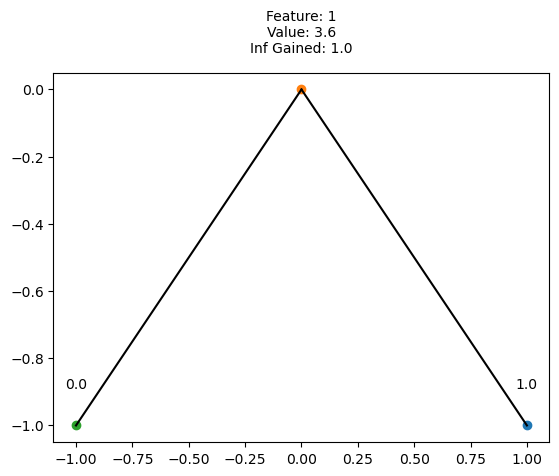

Test 2 (2D): [1. 1. 0. 0.]


In [ ]:
X2 = np.array([
    [10.0, 3.0],
    [ 8.0, 3.4],
    [12.0, 3.2],  # class 0 below 3.5
    [ 9.0, 3.8],
    [11.5, 4.1],
    [ 7.5, 5.0],  # class 1 above 3.5
])
y2 = np.array([0, 0, 0, 1, 1, 1])
tree = Decision_Tree()
tree.train(X2, y2)
X2 = np.array([[50, 4], [0, 4], [50, 2], [0, 2]])
res = tree.predict(X2)
tree.print_tree()
print("Test 2 (2D):", res)
# expected: feature 1, threshold ~ 3.5

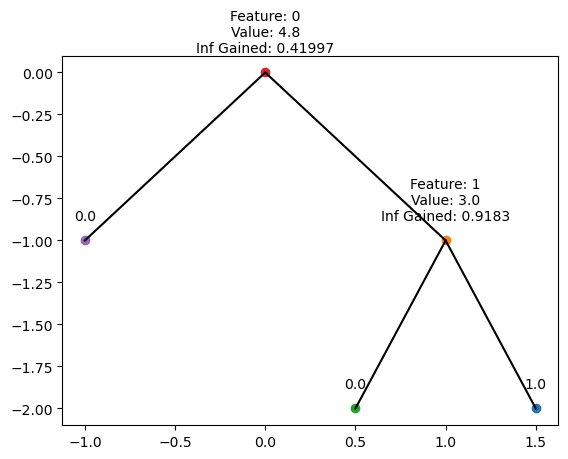

In [ ]:
data = np.array([
    [1.0, 1.0, 0, 0, 0, 0, 0, 0, 0, 0],  # x0<=5 -> 0
    [2.0, 7.0, 0, 0, 0, 0, 0, 0, 0, 0],
    [4.5, 0.0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0.2, 9.0, 0, 0, 0, 0, 0, 0, 0, 0],

    [6.0, 1.0, 0, 0, 0, 0, 0, 0, 0, 0],  # x0>5 & x1<=3 -> 0
    [6.5, 2.5, 0, 0, 0, 0, 0, 0, 0, 0],

    [5.5, 3.5, 0, 0, 0, 0, 0, 0, 0, 1],  # x0>5 & x1>3 -> 1
    [9.0, 9.0, 0, 0, 0, 0, 0, 0, 0, 1],
    [7.2, 4.0, 0, 0, 0, 0, 0, 0, 0, 1],
    [5.1, 8.0, 0, 0, 0, 0, 0, 0, 0, 1],
], dtype=float)


X = data[:, :-1]
y = data[:, -1].astype(int)

tree = Decision_Tree()
tree.train(X, y)
tree.print_tree()

In [19]:
import numpy as np
from utils.decision_tree import Decision_Tree
from utils.random_forest import Random_Forest

data = np.array([
    [1, 5, 0], [2, 4, 0], [3, 2, 0], [4, 7, 1], [5, 6, 1], [6, 5, 1], [7, 8, 1], [8, 9, 1], [9, 1, 0], [10, 2, 0], [11, 3, 0], [12, 0, 1]
], dtype=float)

X = data[:, :-1]
y = data[:, -1].astype(int)

tree = Random_Forest()
tree.train(X, y)

x_test = np.array([
    [1, 2],
    [2, 3],
    [4, 6],
    [0, 5]
])

print(tree.predict(x_test))

[0. 0. 1. 1.]
